# Sales Prediction using Advertising Dataset
Predict product **Sales** from advertising spend on **TV**, **Radio** and **Newspaper** using regression models.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
%matplotlib inline

## 1. Load data

In [2]:
df = pd.read_csv('../data/advertising.csv')
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [4]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

## 2. Exploratory Data Analysis

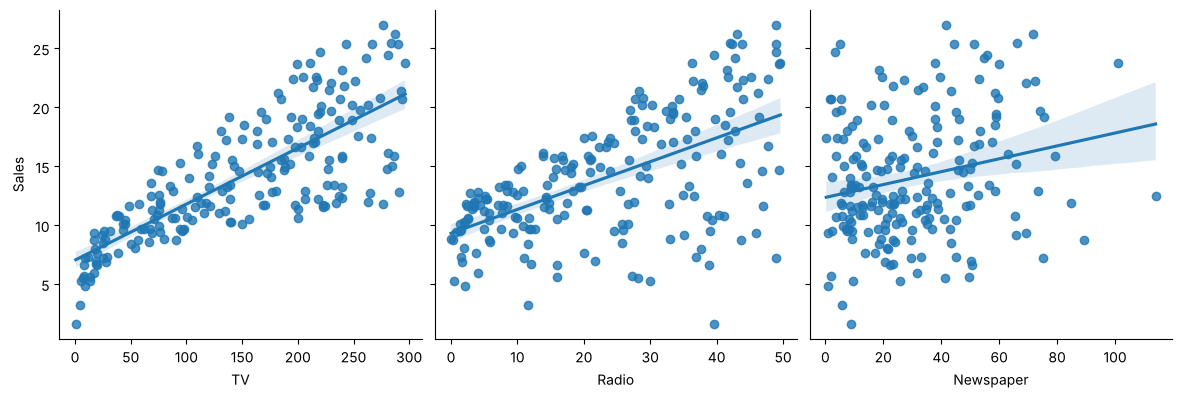

In [5]:
sns.pairplot(df, x_vars=['TV','Radio','Newspaper'], y_vars='Sales', height=4, kind='reg')
plt.show()

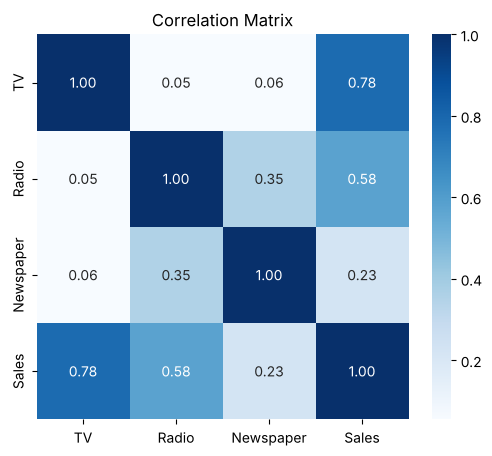

In [6]:
plt.figure(figsize=(6,5))
sns.heatmap(df.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix'); plt.show()

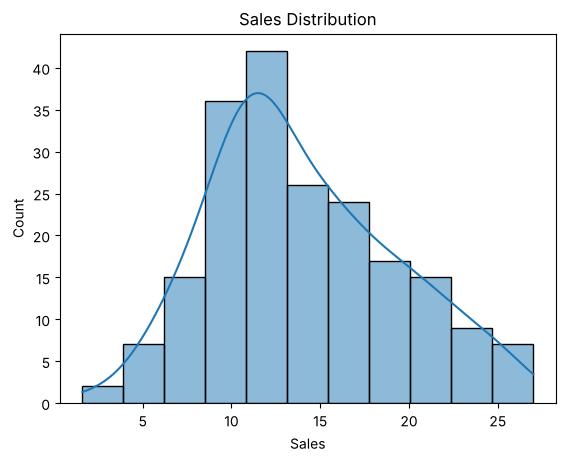

In [7]:
sns.histplot(df['Sales'], kde=True); plt.title('Sales Distribution'); plt.show()

**Observation:** TV has the strongest correlation with Sales, followed by Radio. Newspaper shows weak correlation.

## 3. Train / Test split

In [8]:
X = df[['TV','Radio','Newspaper']]
y = df['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((160, 3), (40, 3))

## 4. Model training & comparison

In [9]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({'Model': name, 'R2': r2_score(y_test, p), 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'CV_R2_mean': cross_val_score(m, X, y, cv=5, scoring='r2').mean()})
results = pd.DataFrame(rows).sort_values('R2', ascending=False)
results.round(4)

,Model,R2,MAE,RMSE,CV_R2_mean
2,Gradient Boosting,0.9831,0.6187,0.7298,0.9775
1,Random Forest,0.9818,0.6289,0.7577,0.9758
0,Linear Regression,0.8994,1.4608,1.7816,0.8871


## 5. Linear Regression interpretation

In [10]:
lr = models['Linear Regression']
print('Intercept:', round(lr.intercept_, 4))
pd.Series(lr.coef_, index=X.columns, name='Coefficient')

Intercept: 2.9791


TV           0.044730
Radio        0.189195
Newspaper    0.002761
Name: Coefficient, dtype: float64

## 6. Best model evaluation

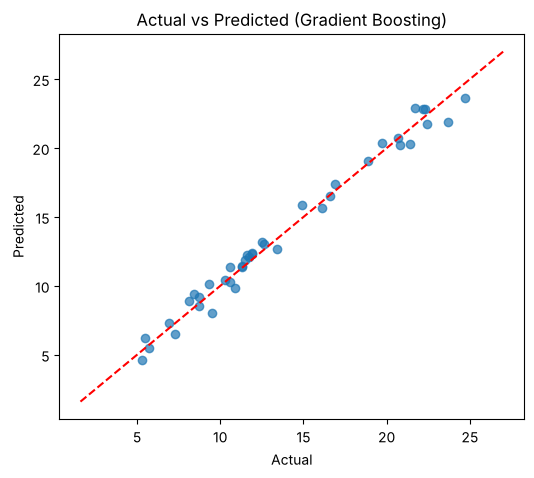

In [11]:
best_name = results.iloc[0]['Model']; best = models[best_name]
pred = best.predict(X_test)
plt.figure(figsize=(6,5)); plt.scatter(y_test, pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title(f'Actual vs Predicted ({best_name})'); plt.show()

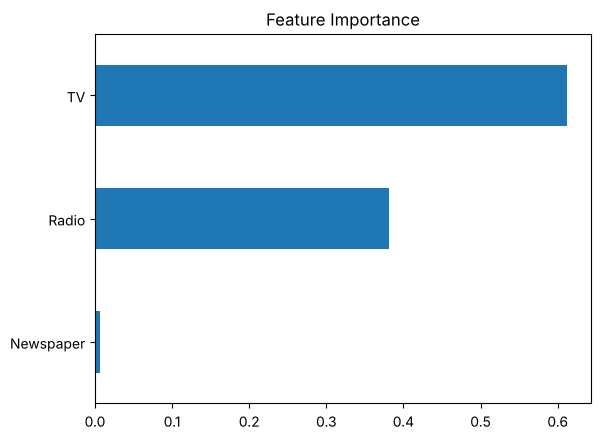

In [12]:
pd.Series(best.feature_importances_, index=X.columns).sort_values().plot(kind='barh', title='Feature Importance'); plt.show()

## 7. Predict for a new budget

In [13]:
new = pd.DataFrame([[150, 25, 20]], columns=['TV','Radio','Newspaper'])
print(f'Predicted Sales: {best.predict(new)[0]:.2f}')

Predicted Sales: 14.69


## 8. Conclusion
- Ensemble models (Gradient Boosting / Random Forest) reach **R² ≈ 0.98** vs ≈ 0.90 for Linear Regression, capturing the TV × Radio interaction.
- **TV** and **Radio** drive sales; **Newspaper** spend has negligible impact.
- Business takeaway: shift budget from Newspaper toward TV and Radio.